# Revised case (v2): costed battery, hourly demand with hydrogen storage, merchant hydrogen

`tvef_model` now carries two case configurations (`tm.CASES`, selected with `make_inputs(data, case=...)` and
`H2SystemTree(..., case=...)`):

| | `legacy` (ChemSus case study) | `v2` |
|---|---|---|
| battery | 200 MWh bound, fixed 25 MW rating with no capex, 1,250 USD/MWh energy cost (not annualized) | annualized energy and power capex (`tm.BATTERY_COSTED`), one sized rating for charge and discharge, loose bounds |
| hydrogen demand | daily totals (free, unlimited intraday buffer) | hourly targets, daily series interpolated between day centres |
| hydrogen storage | none | compressed-gas buffer with compressor power draw (`tm.H2_STORAGE`) |
| demand slack | four emission-free penalty tiers D1 to D4 | merchant hydrogen at a market price with its own scope-3 intensity (`merchant_h2_ef` handle, `tm.MERCHANT_H2`) |
| intensity cap basis | own hydrogen (delivered minus tiers) | all delivered hydrogen (merchant hydrogen carries its emissions) |
| process capex | per-(kg/hr) figures of the case study (0.2 to 1.5 USD per kg/hr), effectively free capacity | installed costs from the IEA Future of Hydrogen (2019) annex, annualized with the same capital recovery factor (8 %, 25 years) plus fixed O&M as a fraction of installed cost (`tm.PROCESS_COSTED`) |

The legacy configuration is the default, so the earlier notebooks reproduce their numbers unchanged.

__author__ = "Marco De Sousa"
__copyright__ = "Copyright 2023, Multi-parametric Optimization & Control Lab"
__credits__ = ["Marco De Sousa", "Rahul Kakodkar", "Efstratios N. Pistikopoulos"]
__license__ = "MIT"
__version__ = "1.2.0"
__maintainer__ = "Marco De Sousa"
__email__ = "marcopdsousa@tamu.edu"
__status__ = "Production"

In [1]:
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tvef_model as tm
from tvef_model import H2System, make_inputs, PARAMS

data = tm.load_case_data()
pd.set_option('display.width', 200)

print('battery (costed) :', {k: round(v, 1) for k, v in tm.BATTERY_COSTED.items() if 'annual' in k}, 'USD per MWh / MW per year')
print('hydrogen storage :', {k: round(v, 1) for k, v in tm.H2_STORAGE.items() if 'annual' in k}, 'USD per kg / (kg/hr) per year')
print('merchant hydrogen:', tm.MERCHANT_H2, '; intensity handle:', PARAMS.loc['merchant_h2_ef', ['nominal', 'low', 'high']].to_dict())
display(pd.DataFrame(tm.CASES).T)
print('process economics (USD per kg/hr of capacity; capex_annual = installed x CRF(8 %, life), fopex_annual = installed x FOM fraction):')
tm.process_cost_table().round(1)

battery (costed) : {'energy_capex_annual': 35457.4, 'power_capex_annual': 17524.4, 'power_fopex_annual': 3750.0} USD per MWh / MW per year
hydrogen storage : {'storage_capex_annual': 55.9, 'compressor_capex_annual': 262.9, 'compressor_fopex_annual': 90.0} USD per kg / (kg/hr) per year
merchant hydrogen: {'price': 5.0, 'cons_max': 100000000.0} ; intensity handle: {'nominal': 10.0, 'low': 9.0, 'high': 12.0}


,battery,demand,h2_storage,slack,process_capex,prorate_capex,demand_shape,demand_interp,battery_cost_scale,h2_storage_cost_scale,process_cost_scale
legacy,legacy,daily,False,tiers,legacy,False,None,False,1.0,1.0,1.0
v2,costed,hourly,True,merchant,annualized,True,None,True,1.0,1.0,1.0


process economics (USD per kg/hr of capacity; capex_annual = installed x CRF(8 %, life), fopex_annual = installed x FOM fraction):


,installed_per_kw,kw_per_unit,capex_installed,fom_fraction,life_years,capex_annual,fopex_annual,legacy_capex,legacy_fopex
SMR,910.0,33.3,30333.3,0.0,25.0,2841.6,1425.7,0.2,0.1
SMRCCS,770.0,33.3,25666.7,0.0,25.0,2404.4,770.0,0.4,0.1
ATR_CCS_R,1680.0,33.3,56000.0,0.0,25.0,5246.0,1680.0,0.4,0.1
ATR_CCS_R_OC,1680.0,33.3,56000.0,0.0,25.0,5246.0,1680.0,0.4,0.1
PEM,900.0,52.0,46800.0,0.0,25.0,4384.2,702.0,1.5,0.7
AWE,900.0,60.0,54000.0,0.0,25.0,5058.7,810.0,0.8,0.2


## Cost optimum: legacy versus v2

The legacy process capex figures are tiny (the whole capex line is under 0.2 M USD on a 258 M USD annual cost), so
reforming and electrolysis capacity was effectively free and the reformers were oversized to buy ramp room, while the
battery and the hydrogen storage paid realistic annualized costs. In v2 the production processes are now annualized
the same way (installed cost x capital recovery factor + fixed O&M), so capacity, storage and merchant hydrogen compete
on a consistent basis. The third column, v2 with the legacy process capex, isolates the effect of the annualization.

In [2]:
TIME_LIMIT = 1200   # s per solve; a hard or infeasible target is reported as 'timeLimit' instead of blocking the sweep


def solve_case(case, objective='cost', demand_sign='eq', cap=None, intensity=None, gamma=None, cp=None, time_limit=TIME_LIMIT, **case_kw):
    """cp: kwargs of H2System.add_4cp_charge (e.g. dict(mode='window', basis='gross')) to add the ERCOT 4CP charge."""
    inp = make_inputs(data, case=case, **case_kw)
    m = H2System(inp, objective, demand_sign)
    if cp is not None:
        m.add_4cp_charge(**cp)
    if gamma:
        m.add_robust_gwp_cap(cap=cap, intensity=intensity, gamma=gamma, band='0.75')
    elif cap is not None or intensity is not None:
        m.add_gwp_cap(cap=cap, intensity=intensity)
    st = m.solve(tee=False, TimeLimit=time_limit)
    row = dict(case=inp['case']['name'], status=st, build_s=m.build_time, solve_s=m.solve_time)
    if st == 'optimal':
        r, fr = m.results(), m.frames()
        rv = m.robust_values() if gamma else {}
        row.update({'cost [M USD]': (m.Cost.getValue() if objective != 'cost' else r['objective']) / 1e6,
                    'capex [k USD]': r['Capex_network'][0] / 1e3,
                    'GWP [kt]': r['global_warming_potential_network'][0] / 1e6,
                    **{f'scope {s} [kt]': r['global_warming_potential_scope'][('BG', s, 0)] / 1e6 for s in (1, 2, 3)},
                    'intensity': r['gwp_intensity'], 'worst-case intensity': rv.get('worst_case_intensity', r['gwp_intensity']),
                    'own H2 [kt]': r['H2_own'] / 1e6, 'slack H2 [kt]': r['H2_penalty'] / 1e6,
                    'SMR': fr['Cap_P']['SMR'], 'SMRCCS': fr['Cap_P']['SMRCCS'], 'ATR_CCS_R': fr['Cap_P']['ATR_CCS_R'],
                    'ATR_CCS_R_OC': fr['Cap_P']['ATR_CCS_R_OC'], 'PEM': fr['Cap_P']['PEM'], 'AWE': fr['Cap_P']['AWE'],
                    'grid [MW]': fr['Cap_P']['Grid'], 'battery [MWh]': fr['Cap_S'].get(tm.LiI_stored, 0.0),
                    'battery [MW]': fr['Cap_P']['LiI'], 'H2 storage [kg]': fr['Cap_S'].get(tm.H2_stored, 0.0),
                    'compressor [kg/hr]': fr['Cap_P'].get('H2_compress', 0.0),
                    'battery cycles': (fr['P'].loc['LiI'].sum() / fr['Cap_S'][tm.LiI_stored] if fr['Cap_S'].get(tm.LiI_stored, 0.0) > 1e-6 else 0.0),
                    'H2 storage cycles': (fr['P'].loc['H2_compress'].sum() / fr['Cap_S'][tm.H2_stored]
                                          if 'H2_compress' in fr['P'].index and fr['Cap_S'].get(tm.H2_stored, 0.0) > 1e-6 else 0.0)})
        g = fr['P'].loc['Grid'].to_numpy()
        pv, wf = (tm.PROCESSES[q]['conversion'][tm.Power] * fr['P'].loc[q].to_numpy() for q in ('PV', 'WF'))   # power output [MW]
        t_cp = [tm._hour_index(mo, *dh) for mo, dh in tm.ERCOT_4CP_2025.items()]
        row.update({'4CP charge [k USD]': r.get('demand_charge_4cp', 0.0) / 1e3,
                    'grid at 4CP [MW]': float(np.mean(g[t_cp])), 'gross at 4CP [MW]': float(np.mean(g[t_cp] + pv[t_cp] + wf[t_cp])),
                    'grid [GWh]': g.sum() / 1e3, 'PPA [GWh]': (pv.sum() + wf.sum()) / 1e3})
        row['_frames'] = fr
    del m
    return row


t0 = time.time()
base_rows = {'legacy': solve_case('legacy'), 'v2': solve_case('v2'), 'v2 (legacy capex)': solve_case('v2', process_capex='legacy')}
print(f'3 solves in {time.time() - t0:.0f} s')
base = pd.DataFrame({c: {k: v for k, v in r.items() if not k.startswith('_')} for c, r in base_rows.items()})
I0 = {c: base_rows[c]['intensity'] for c in ('legacy', 'v2')}
peak_demand = make_inputs(data, case='v2')['h2_demand_hourly'].max()
cap_cols = ['SMR', 'ATR_CCS_R', 'ATR_CCS_R_OC', 'PEM', 'AWE']
base.loc['H2 capacity / peak demand'] = base.loc[cap_cols].astype(float).sum() / peak_demand
base.round(3)

Set parameter Username


Academic license - for non-commercial use only - expires 2027-03-30


3 solves in 192 s


,legacy,v2,v2 (legacy capex)
case,legacy,v2,v2
status,optimal,optimal,optimal
build_s,16.827993,14.944503,15.300173
solve_s,38.102296,40.96289,54.738137
cost [M USD],257.643902,318.069263,259.332507
capex [k USD],182.43787,38809.216043,41.443448
GWP [kt],1447.319756,1445.650367,1446.184534
scope 1 [kt],1038.794998,1034.626151,1038.689392
scope 2 [kt],31.945361,31.507596,30.903097
scope 3 [kt],376.579396,379.51662,376.592045


With the process capex annualized the cost optimum rises from 259 M USD (v2 with the legacy capex) to 318 M USD, of
which 39 M USD is annualized capex and a further 19 M USD fixed O&M. The design changes qualitatively: the SMR is sized
at 13.2 t/hr, below the 15.4 t/hr demand peak (capacity / peak demand 0.85 against 2.2 with the legacy capex), and the
peak is covered by 21 t of compressed hydrogen storage (65 cycles per year) plus 0.4 kt of merchant hydrogen. The
battery is still not built: its arbitrage value on the ERCOT price spread (a few thousand USD per MWh per year) is
below its annualized cost (about 35,000 USD per MWh per year). The emission intensity of the cost optima is the same
within 0.1 % across the three columns, so the 50 % target of the sweeps carries over.

## How much capacity margin does the ramp room buy? Process cost scaling

With free capacity the optimizer oversizes the reformers (ramp and smoothing limits are fractions of installed
capacity, so a bigger plant can follow the demand more easily). Scaling the annualized process costs from the
reference value down to zero shows how fast that margin disappears once capacity has a price, and what replaces it
(hydrogen storage, merchant hydrogen, or simply running closer to the demand).

In [3]:
pscales = [1.0, 0.5, 0.25, 0.1, 0.0]
t0 = time.time()
pscale_rows = []
for k in pscales:
    r = solve_case('v2', process_cost_scale=k)
    r['process cost scale'] = k
    r['H2 capacity / peak demand'] = sum(r[p] for p in cap_cols) / peak_demand
    pscale_rows.append({kk: v for kk, v in r.items() if not kk.startswith('_')})
print(f'{len(pscales)} solves in {time.time() - t0:.0f} s')
pscale_df = pd.DataFrame(pscale_rows).set_index('process cost scale')
pscale_df[['status', 'cost [M USD]', 'capex [k USD]', 'GWP [kt]', 'intensity', 'H2 capacity / peak demand', 'SMR', 'ATR_CCS_R', 'PEM',
           'slack H2 [kt]', 'battery [MWh]', 'H2 storage [kg]', 'compressor [kg/hr]']].round(3)

5 solves in 388 s


,status,cost [M USD],capex [k USD],GWP [kt],intensity,H2 capacity / peak demand,SMR,ATR_CCS_R,PEM,slack H2 [kt],battery [MWh],H2 storage [kg],compressor [kg/hr]
process cost scale,,,,,,,,,,,,,
1.00,optimal,318.069,38809.216,1445.650,13.042,0.854,13154.850,0.001,0.001,0.445,0.0,21286.217,905.602
0.50,optimal,289.590,20086.434,1446.006,13.045,0.887,13664.078,0.001,0.001,0.187,0.0,9565.951,523.403
0.25,optimal,274.806,10200.406,1445.920,13.044,0.915,14103.685,0.001,0.001,0.113,0.0,2270.485,206.185
0.10,optimal,265.657,4191.171,1446.045,13.045,0.942,14505.896,0.001,0.001,0.046,0.0,440.496,169.489
0.00,optimal,259.322,34.202,1446.251,13.047,2.306,33485.029,0.001,2034.000,0.006,0.0,136.450,101.083


## Intensity floor: the lowest intensity each case can reach

Minimizing emissions outright gives the floor of achievable intensity. In the legacy case the floor is reached by
replacing almost all production with emission-free penalty hydrogen; in v2 the merchant hydrogen carries 10 kg CO2e
per kg, so the floor is set by the plant itself: electrolysis on the PPA power that is available, and ATR with capture
for the rest. Targets below the floor are infeasible, which the sweeps below respect.

In [4]:
t0 = time.time()
floor_rows = {c: solve_case(c, objective='gwp') for c in ('legacy', 'v2')}
print(f'2 solves in {time.time() - t0:.0f} s')
floor = pd.DataFrame({c: {k: v for k, v in r.items() if not k.startswith('_')} for c, r in floor_rows.items()})
I_min = {c: floor_rows[c]['intensity'] for c in floor_rows}
max_reduction = {c: 100 * (1 - I_min[c] / I0[c]) for c in I0}
for c in I0:
    print(f'{c:7s}: cost-optimal intensity {I0[c]:.3f}, floor {I_min[c]:.3f} kg CO2e/kg H2  ->  deepest feasible target {max_reduction[c]:.1f} %')
floor.loc[['status', 'cost [M USD]', 'GWP [kt]', 'intensity', 'own H2 [kt]', 'slack H2 [kt]', 'SMR', 'ATR_CCS_R', 'PEM', 'AWE',
           'grid [MW]', 'battery [MWh]', 'H2 storage [kg]']].T.round(3)

2 solves in 89 s
legacy : cost-optimal intensity 13.057, floor 0.457 kg CO2e/kg H2  ->  deepest feasible target 96.5 %
v2     : cost-optimal intensity 13.042, floor 2.913 kg CO2e/kg H2  ->  deepest feasible target 77.7 %


,status,cost [M USD],GWP [kt],intensity,own H2 [kt],slack H2 [kt],SMR,ATR_CCS_R,PEM,AWE,grid [MW],battery [MWh],H2 storage [kg]
legacy,optimal,7571.475556,2.228424,0.456999,4.876212,105.972339,0.001,0.001,39799.0,4674.0,2058.0,200.0,0.0
v2,optimal,1394.60747,322.933512,2.913286,110.848551,0.0,0.001,31289.509397,6313.0,1.0,1.0,10000.0,3000000.0


## When does storage get built? Cost scaling under the 50 % intensity target

The battery and hydrogen storage costs are scaled together (`battery_cost_scale`, `h2_storage_cost_scale`) under the
50 % intensity cap, which is where time-shifting has emission value as well as price value. With priced capacity the
hydrogen storage is now part of the reference design (19 t at scale 1), while the battery still needs its cost to fall
to a quarter of the reference value before it is built.

In [5]:
scales = [1.0, 0.5, 0.25, 0.1, 0.05, 0.02]
t0 = time.time()
scale_rows = []
for k in scales:
    r = solve_case('v2', demand_sign='geq', intensity=0.5 * I0['v2'], battery_cost_scale=k, h2_storage_cost_scale=k)
    r['cost scale'] = k
    scale_rows.append({kk: v for kk, v in r.items() if not kk.startswith('_')})
print(f'{len(scales)} solves in {time.time() - t0:.0f} s')
scale_df = pd.DataFrame(scale_rows).set_index('cost scale')
scale_df[['status', 'cost [M USD]', 'GWP [kt]', 'intensity', 'battery [MWh]', 'battery [MW]', 'battery cycles',
          'H2 storage [kg]', 'compressor [kg/hr]', 'H2 storage cycles', 'slack H2 [kt]', 'SMR', 'ATR_CCS_R', 'PEM']].round(3)

6 solves in 759 s


,status,cost [M USD],GWP [kt],intensity,battery [MWh],battery [MW],battery cycles,H2 storage [kg],compressor [kg/hr],H2 storage cycles,slack H2 [kt],SMR,ATR_CCS_R,PEM
cost scale,,,,,,,,,,,,,,
1.00,optimal,363.341,722.825,6.521,0.000,0.000,0.000,19247.356,795.440,56.016,0.519,3338.190,9802.020,0.001
0.50,optimal,362.401,722.825,6.521,0.000,0.000,0.000,36872.376,1343.841,42.739,0.367,3229.895,9812.164,0.001
0.25,optimal,361.108,722.825,6.521,88.028,29.343,551.152,57468.876,1675.849,32.156,0.267,3159.758,9842.062,0.001
0.10,optimal,359.432,722.825,6.521,284.966,94.989,394.360,113295.574,2216.266,19.089,0.202,3083.622,9847.088,0.001
0.05,optimal,358.145,722.825,6.521,495.670,247.835,341.105,156023.380,2299.848,14.877,0.115,3165.068,9834.324,0.001
0.02,optimal,356.652,722.825,6.521,1229.775,558.025,169.012,1044164.243,9735.048,3.309,0.068,3239.304,9909.135,0.001


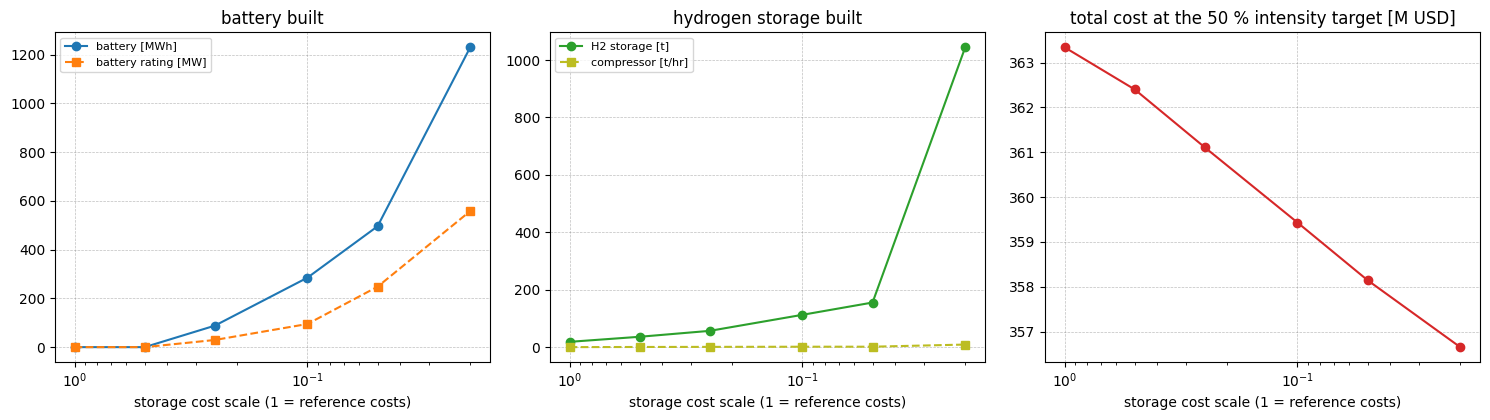

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
x = scale_df.index.to_numpy()
axes[0].plot(x, scale_df['battery [MWh]'], 'o-', label='battery [MWh]')
axes[0].plot(x, scale_df['battery [MW]'], 's--', label='battery rating [MW]')
axes[1].plot(x, scale_df['H2 storage [kg]'] / 1e3, 'o-', color='tab:green', label='H2 storage [t]')
axes[1].plot(x, scale_df['compressor [kg/hr]'] / 1e3, 's--', color='tab:olive', label='compressor [t/hr]')
axes[2].plot(x, scale_df['cost [M USD]'], 'o-', color='tab:red')
for ax, title in zip(axes, ['battery built', 'hydrogen storage built', 'total cost at the 50 % intensity target [M USD]']):
    ax.set_xscale('log')
    ax.invert_xaxis()
    ax.set_xlabel('storage cost scale (1 = reference costs)')
    ax.set_title(title)
    ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
    if ax is not axes[2]:
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Intensity-cap sweep: legacy versus v2

Both cases are swept over the same relative intensity targets (10 % to 90 % below their own cost-optimal intensity).
The legacy case meets deep targets by shrinking output and buying emission-free penalty hydrogen; in v2 the merchant
hydrogen carries 10 kg CO2e per kg, so deep targets have to be met by the plant itself, and targets below the
intensity floor are infeasible (skipped).

In [7]:
targets = list(range(10, 100, 10))
t0 = time.time()
sweep_rows = []
for c in ('legacy', 'v2'):
    for pct in targets:
        if pct > max_reduction[c]:
            r = dict(case=c, status='infeasible (below floor)', solve_s=0.0)
        else:
            r = solve_case(c, demand_sign='geq', intensity=I0[c] * (1 - pct / 100))
        r['target [%]'] = pct
        sweep_rows.append({kk: v for kk, v in r.items() if not kk.startswith('_')})
        print(f"{c:7s} {pct:3d} %  {r['status']:10s}  {r.get('cost [M USD]', float('nan')):9.2f} M USD  slack {r.get('slack H2 [kt]', float('nan')):7.2f} kt  ({r['solve_s']:.0f} s)")
print(f'{len(sweep_rows)} solves in {time.time() - t0:.0f} s')
sweep_df = pd.DataFrame(sweep_rows).set_index(['case', 'target [%]'])
sweep_df[['status', 'cost [M USD]', 'GWP [kt]', 'intensity', 'own H2 [kt]', 'slack H2 [kt]', 'SMR', 'ATR_CCS_R', 'ATR_CCS_R_OC',
          'PEM', 'AWE', 'battery [MWh]', 'H2 storage [kg]']].round(3)

legacy   10 %  optimal        260.73 M USD  slack    0.00 kt  (74 s)


legacy   20 %  optimal        263.95 M USD  slack    0.00 kt  (114 s)


legacy   30 %  optimal        267.39 M USD  slack    0.00 kt  (133 s)


legacy   40 %  optimal        271.07 M USD  slack    0.00 kt  (147 s)


legacy   50 %  optimal        274.91 M USD  slack    0.00 kt  (81 s)


legacy   60 %  optimal        278.81 M USD  slack    0.00 kt  (152 s)


... (7 outputs left out)

v2       50 %  optimal        363.34 M USD  slack    0.52 kt  (199 s)


v2       60 %  optimal        372.58 M USD  slack    0.56 kt  (38 s)


v2       70 %  optimal        398.47 M USD  slack    0.38 kt  (37 s)
v2       80 %  infeasible (below floor)        nan M USD  slack     nan kt  (0 s)
v2       90 %  infeasible (below floor)        nan M USD  slack     nan kt  (0 s)
18 solves in 1730 s


status  cost [M USD]  GWP [kt]  intensity  own H2 [kt]  slack H2 [kt]        SMR  ATR_CCS_R  ATR_CCS_R_OC       PEM    AWE  battery [MWh]  H2 storage [kg]
case   target [%]                                                                                                                                                                              
legacy 10                           optimal       260.728  1302.588     11.751      110.849          0.000  18741.872   5081.431         0.001     0.001  0.001        175.000            0.000
       20                           optimal       263.950  1157.856     10.445      110.849          0.000  14066.273   9796.612         0.001     0.001  0.001        190.722            0.000
       30                           optimal       267.392  1013.124      9.140      110.849          0.000  10655.122  14340.665         0.001     0.001  0.001        200.000            0.000
       40                           optimal       271.068   868.392      7.834      110.849          0.000   8091.257  18596.144         0.001     0.001  0.001        200.000            0.000
       50                           optimal       274.909   723.660      6.528      110.849          0.000   4920.837  22551.544         0.001     0.001  0.001        200.000            0.000
       60                           optimal       278.809   578.928      5.223      110.849          0.000   1507.594  26152.816         0.001     0.001  0.001        200.000            0.000
       70                           optimal       302.200   434.196      3.917      110.849          0.000      0.001  27550.309         0.001     0.001  0.001        100.000            0.000
       80                           optimal      1190.229   210.449      2.611       80.590         30.258      0.001  14164.622         0.001  6262.012  0.001         36.672            0.000
       90                           optimal      4091.668    48.247      1.306       36.952         73.897      0.001   1995.770         0.001  6388.954  0.001        200.000            0.000
v2     10                           optimal       327.110  1301.085     11.738      110.335          0.514  11186.650   1955.111         0.001     0.001  0.001          0.000        19351.915
       20                           optimal       336.166  1156.520     10.433      110.335          0.513   9225.052   3916.776         0.001     0.001  0.001          0.000        19358.896
       30                           optimal       345.222  1011.955      9.129      110.335          0.513   7263.388   5878.440         0.001     0.001  0.001          0.000        19358.896
       40                           optimal       354.279   867.390      7.825      110.333          0.515   5301.241   7840.161         0.001     0.001  0.001          0.000        19316.320
       50                           optimal       363.341   722.825      6.521      110.330          0.519   3338.190   9802.020         0.001     0.001  0.001          0.000        19247.356
       60                           optimal       372.580   578.260      5.217      110.291          0.558   1258.858  11803.353         0.001     0.001  0.001          0.000        22437.508
       70                           optimal       398.474   433.695      3.913      110.471          0.378      0.001  13109.920         0.001     0.001  0.001          0.000        27698.725
       80          infeasible (below floor)           NaN       NaN        NaN          NaN            NaN        NaN        NaN           NaN       NaN    NaN            NaN              NaN
       90          infeasible (below floor)           NaN       NaN        NaN          NaN            NaN        NaN        NaN           NaN       NaN    NaN            NaN              NaN

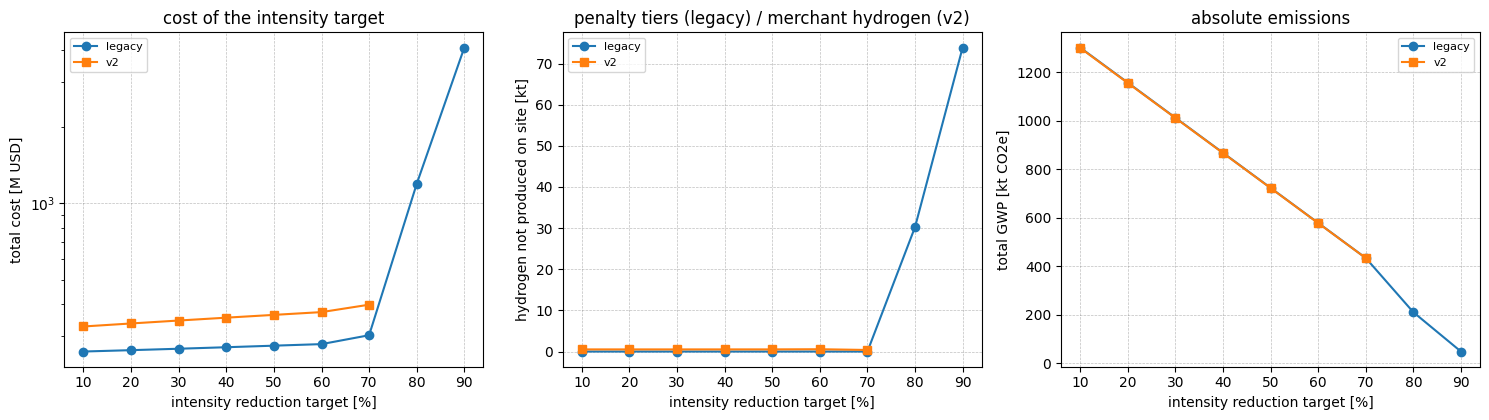

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for c, mk in (('legacy', 'o-'), ('v2', 's-')):
    sub = sweep_df.xs(c, level='case')
    ok = sub['status'] == 'optimal'
    axes[0].plot(sub.index[ok], sub.loc[ok, 'cost [M USD]'], mk, label=c)
    axes[1].plot(sub.index[ok], sub.loc[ok, 'slack H2 [kt]'], mk, label=c)
    axes[2].plot(sub.index[ok], sub.loc[ok, 'GWP [kt]'], mk, label=c)
for ax, yl, title in zip(axes, ['total cost [M USD]', 'hydrogen not produced on site [kt]', 'total GWP [kt CO2e]'],
                         ['cost of the intensity target', 'penalty tiers (legacy) / merchant hydrogen (v2)', 'absolute emissions']):
    ax.set_xlabel('intensity reduction target [%]')
    ax.set_ylabel(yl)
    ax.set_title(title)
    ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
    ax.legend(fontsize=8)
axes[0].set_yscale('log')
plt.tight_layout()
plt.show()

## Robust scope-3 budget in v2 under the 50 % intensity target

Scope 3 now has two uncertain factors, the upstream gas factor (0.96 to 2.5 kg CO2e per kg NG) and the merchant
hydrogen intensity (10 to 12 kg CO2e per kg), so the budget runs from 0 to 2. Because the slack supply carries
emissions, there is no longer a way to buy compliance: beyond some budget the target is infeasible, which is the
honest answer that the emission-free tiers used to hide. Infeasibility is detected with a robust floor (the lowest
worst-case intensity the plant can guarantee under the budget) rather than left to the solver, which can take very
long to prove an infeasible instance of this size. The floors do not depend on the cost data, so they are the same as
before the capex annualization; the price of robustness is what changes.

In [9]:
def robust_floor(case, gamma, band='0.75'):
    """Lowest worst-case intensity reachable under the budgets: minimize nominal GWP + robust margin with the demand
    met exactly (the denominator is then fixed). A target below this floor is infeasible for these budgets."""
    m = H2System(make_inputs(data, case=case), 'gwp', 'eq')
    m.add_robust_gwp_cap(cap=tm.bigM * 1e3, gamma=gamma, band=band)          # creates z, q and the margin expressions
    margin = sum(m.robust['margin'].values())
    m.m.setObjective(m.gwp_total + margin, tm.GRB.MINIMIZE)
    st = m.solve(tee=False, TimeLimit=TIME_LIMIT)
    out = (m.robust_values()['worst_case_intensity'] if st == 'optimal' else np.nan, st, m.solve_time)
    del m
    return out


gammas3 = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
target3 = 0.5 * I0['v2']
t0 = time.time()
floors3 = {}
for g in gammas3:
    floors3[g] = robust_floor('v2', {3: g}) if g > 0 else (I_min['v2'], 'optimal', 0.0)
    print(f'gamma3 {g:4.2f}: worst-case intensity floor {floors3[g][0]:.3f} kg CO2e/kg H2 ({floors3[g][1]}, {floors3[g][2]:.0f} s)'
          f'{"  -> target " + format(target3, ".3f") + " infeasible" if floors3[g][0] > target3 else ""}')
print(f'{len(gammas3)} floor solves in {time.time() - t0:.0f} s')

gamma3 0.00: worst-case intensity floor 2.913 kg CO2e/kg H2 (optimal, 0 s)


gamma3 0.25: worst-case intensity floor 3.931 kg CO2e/kg H2 (optimal, 32 s)


gamma3 0.50: worst-case intensity floor 4.949 kg CO2e/kg H2 (optimal, 43 s)


gamma3 0.75: worst-case intensity floor 5.967 kg CO2e/kg H2 (optimal, 57 s)


gamma3 1.00: worst-case intensity floor 6.985 kg CO2e/kg H2 (optimal, 39 s)  -> target 6.521 infeasible


gamma3 1.50: worst-case intensity floor 6.985 kg CO2e/kg H2 (optimal, 65 s)  -> target 6.521 infeasible


gamma3 2.00: worst-case intensity floor 6.985 kg CO2e/kg H2 (optimal, 32 s)  -> target 6.521 infeasible
7 floor solves in 364 s


In [10]:
t0 = time.time()
rob_rows = []
for g in gammas3:
    if floors3[g][0] > target3 * (1 + 1e-6):
        r = dict(case='v2', status='infeasible (above robust floor)', solve_s=0.0)
    else:
        r = solve_case('v2', demand_sign='geq', intensity=target3, gamma={3: g} if g > 0 else None)
    r['gamma 3'] = g
    r['worst-case floor'] = floors3[g][0]
    rob_rows.append({kk: v for kk, v in r.items() if not kk.startswith('_')})
    print(f"gamma3 {g:4.2f}  {r['status']:22s}  {r.get('cost [M USD]', float('nan')):9.2f} M USD  ({r['solve_s']:.0f} s)")
print(f'{len(gammas3)} solves in {time.time() - t0:.0f} s')
rob_df = pd.DataFrame(rob_rows).set_index('gamma 3')
rob_df[['status', 'worst-case floor', 'cost [M USD]', 'GWP [kt]', 'intensity', 'worst-case intensity', 'slack H2 [kt]', 'SMR', 'ATR_CCS_R',
        'ATR_CCS_R_OC', 'PEM', 'AWE', 'battery [MWh]', 'H2 storage [kg]']].round(3)

gamma3 0.00  optimal                    363.34 M USD  (204 s)


gamma3 0.25  optimal                    372.08 M USD  (281 s)


gamma3 0.50  optimal                    393.58 M USD  (128 s)


gamma3 0.75  optimal                    509.93 M USD  (158 s)
gamma3 1.00  infeasible (above robust floor)        nan M USD  (0 s)
gamma3 1.50  infeasible (above robust floor)        nan M USD  (0 s)
gamma3 2.00  infeasible (above robust floor)        nan M USD  (0 s)
7 solves in 846 s


,status,worst-case floor,cost [M USD],GWP [kt],intensity,worst-case intensity,slack H2 [kt],SMR,ATR_CCS_R,ATR_CCS_R_OC,PEM,AWE,battery [MWh],H2 storage [kg]
gamma 3,,,,,,,,,,,,,,
0.00,optimal,2.913,363.341,722.825,6.521,6.521,0.519,3338.190,9802.020,0.001,0.001,0.001,0.0,19247.356
0.25,optimal,3.931,372.079,585.723,5.284,6.521,0.598,1359.866,11691.874,0.001,0.001,0.001,0.0,21463.670
0.50,optimal,4.949,393.580,450.706,4.066,6.521,0.617,0.001,12987.892,0.001,0.001,0.001,0.0,25707.899
0.75,optimal,5.967,509.933,354.394,3.197,6.521,0.236,0.001,11840.979,0.001,1985.431,0.001,0.0,41460.428
1.00,infeasible (above robust floor),6.985,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1.50,infeasible (above robust floor),6.985,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2.00,infeasible (above robust floor),6.985,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


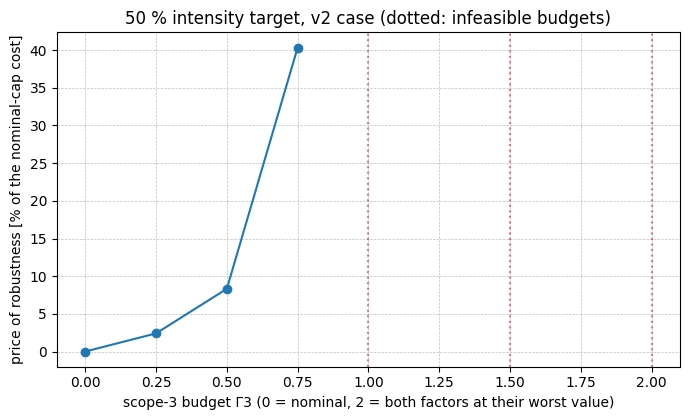

In [11]:
ok = rob_df['status'] == 'optimal'
base_cost = rob_df.loc[0.0, 'cost [M USD]']
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot(rob_df.index[ok], 100 * (rob_df.loc[ok, 'cost [M USD]'] / base_cost - 1), 'o-')
for g in rob_df.index[~ok]:
    ax.axvline(g, color='tab:red', linestyle=':', alpha=0.6)
ax.set_xlabel('scope-3 budget Γ3 (0 = nominal, 2 = both factors at their worst value)')
ax.set_ylabel('price of robustness [% of the nominal-cap cost]')
ax.set_title('50 % intensity target, v2 case (dotted: infeasible budgets)')
ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()

## ERCOT four-coincident-peak (4CP) transmission charge

ERCOT allocates its transmission cost to loads in proportion to their average demand in the four 15-minute intervals
of the system peak in June, July, August and September, at 66.76 USD per kW-year (ERCOT wholesale transmission rate,
2025). `H2System.add_4cp_charge` adds this charge to the cost with three treatments of the peak timing and two
metering bases (`tm.ERCOT_4CP_2025`, `tm.ERCOT_4CP_RATE`, `tm.ERCOT_4CP_WINDOW`):

| timing | charge basis | interpretation |
|---|---|---|
| `known` | the four 2025 intervals (Jun 19, Jul 30, Aug 18 at hour ending 17, Sep 4 at hour ending 18) | perfect foresight of the peaks: the ex-post settlement |
| `window` | the maximum demand over hour endings 16 to 19 of every day of each month | peak timing unknown: the load holds its demand down throughout the window (robust, worst-case timing) |
| `expected` | the average demand over the same window | the load does not respond to peak forecasts (expected charge) |

| basis | metered demand |
|---|---|
| `net` | grid import only: PPA solar and wind are behind the meter and reduce the metered demand |
| `gross` | grid import plus PPA generation: virtual (off-site) PPAs, so only on-site storage or load reduction can lower the metered demand |

The v2 cost optimum draws about 8 MW from the grid around the clock (the PPA power at 53 to 60 USD/MWh is dearer than
the grid at 33 USD/MWh on average, so PV and wind only run when the grid is expensive), which is the exposure the
charge acts on.

In [3]:
cp_variants = {'no charge': None,
               'known / net': dict(mode='known', basis='net'), 'window / net': dict(mode='window', basis='net'),
               'expected / net': dict(mode='expected', basis='net'),
               'known / gross': dict(mode='known', basis='gross'), 'window / gross': dict(mode='window', basis='gross'),
               'expected / gross': dict(mode='expected', basis='gross')}
t0 = time.time()
cp_rows = {}
for label, cp in cp_variants.items():
    r = solve_case('v2', cp=cp)
    r['ex-post charge, known / net [k USD]'] = tm.ERCOT_4CP_RATE * r['grid at 4CP [MW]']          # what each design settles at
    r['ex-post charge, known / gross [k USD]'] = tm.ERCOT_4CP_RATE * r['gross at 4CP [MW]']
    cp_rows[label] = {k: v for k, v in r.items() if not k.startswith('_')}
    print(f"{label:17s} {r['status']:8s} cost {r.get('cost [M USD]', float('nan')):8.3f} M USD  charge {r.get('4CP charge [k USD]', float('nan')):8.1f} k USD  ({r['solve_s']:.0f} s)")
print(f'{len(cp_variants)} solves in {time.time() - t0:.0f} s')
cp_df = pd.DataFrame(cp_rows).T
cp_df[['status', 'cost [M USD]', '4CP charge [k USD]', 'ex-post charge, known / net [k USD]', 'ex-post charge, known / gross [k USD]',
       'grid at 4CP [MW]', 'gross at 4CP [MW]', 'grid [MW]', 'grid [GWh]', 'PPA [GWh]', 'battery [MWh]', 'battery [MW]',
       'H2 storage [kg]', 'SMR', 'slack H2 [kt]']].round(3)

no charge         optimal  cost  318.069 M USD  charge      0.0 k USD  (40 s)


known / net       optimal  cost  318.072 M USD  charge      0.0 k USD  (42 s)


window / net      optimal  cost  318.455 M USD  charge      0.0 k USD  (36 s)


expected / net    optimal  cost  318.455 M USD  charge      0.0 k USD  (59 s)


known / gross     optimal  cost  318.346 M USD  charge      3.8 k USD  (47 s)


window / gross    optimal  cost  318.639 M USD  charge    565.8 k USD  (75 s)


expected / gross  optimal  cost  318.594 M USD  charge    516.0 k USD  (40 s)
7 solves in 474 s


,status,cost [M USD],4CP charge [k USD],"ex-post charge, known / net [k USD]","ex-post charge, known / gross [k USD]",grid at 4CP [MW],gross at 4CP [MW],grid [MW],grid [GWh],PPA [GWh],battery [MWh],battery [MW],H2 storage [kg],SMR,slack H2 [kt]
no charge,optimal,318.069263,0.0,524.363751,524.363751,7.85446,7.85446,10.0,73.446472,0.385737,0.0,0.0,21286.21684,13154.850228,0.444849
known / net,optimal,318.071897,0.0,0.0,518.701605,0.0,7.769647,10.0,73.418129,0.41681,0.0,0.0,21286.217359,13154.850212,0.444849
window / net,optimal,318.45521,0.0,0.0,515.077061,0.0,7.715354,10.0,69.986845,4.107057,0.0,0.0,21323.180802,13155.781249,0.442319
expected / net,optimal,318.45521,0.0,0.0,515.077061,0.0,7.715354,10.0,69.986845,4.107057,0.0,0.0,21323.180802,13155.781249,0.442319
known / gross,optimal,318.346306,3.844031,3.844031,3.844031,0.05758,0.05758,18.0,73.951373,0.213984,7.822155,7.822155,21409.405011,13158.114706,0.437023
window / gross,optimal,318.638728,565.780912,524.325615,524.325615,7.853889,7.853889,10.0,73.453145,0.385709,0.0,0.0,21303.469874,13155.283766,0.444414
expected / gross,optimal,318.593703,516.048015,504.758935,504.758935,7.560799,7.560799,10.0,73.766165,0.382272,0.0,0.0,21353.988139,13156.475546,0.440344


Without the charge the cost optimum would settle at about 0.52 M USD per year (7.9 MW in each 2025 interval). How
much of that is avoidable depends on the metering basis, not on the timing treatment:

- **Net basis (PPAs behind the meter).** The charge is eliminated in every timing treatment by switching the plant to
  PPA wind power in the peak hours. With known intervals this costs 3 k USD; holding the demand down over the whole
  15:00 to 19:00 window of all 122 summer days (robust or expected timing give the same design) costs 0.39 M USD in
  dearer PPA energy, still below the 0.52 M USD it avoids. No storage is needed.
- **Gross basis (virtual PPAs).** PPA power no longer reduces the metered demand, so only on-site storage or load
  reduction can. With known intervals the model builds a battery for the first time at reference cost: 7.8 MWh and
  7.8 MW, discharged in the four intervals, cutting the charge to 4 k USD for 0.28 M USD of extra cost. When the timing
  is uncertain the battery cannot cover a 488-hour window and the plant simply pays the charge (0.57 M USD robust,
  0.52 M USD expected), which is the cheaper option by a small margin.

The 4CP charge is therefore the first mechanism in this case study that gives a battery a role at reference costs, but
only under gross metering and with reliable peak forecasts: the firming value is concentrated in four hours per year,
and it disappears once the timing uncertainty widens to a daily window.

In [4]:
import os
prev = pickle.load(open('Gurobipy_v2_results.pkl', 'rb')) if os.path.exists('Gurobipy_v2_results.pkl') else {}
_g = globals()
keep = lambda var, key: _g.get(var, prev.get(key))      # tables kept from the previous run when only part of the notebook is re-executed
out = {'base': base, 'I0': I0, 'I_min': keep('I_min', 'I_min'), 'floor': keep('floor', 'floor'),
       'storage_cost_scale': keep('scale_df', 'storage_cost_scale'), 'intensity_sweep': keep('sweep_df', 'intensity_sweep'),
       'robust_scope3': keep('rob_df', 'robust_scope3'), 'robust_floors': keep('floors3', 'robust_floors'),
       'process_cost_scale': keep('pscale_df', 'process_cost_scale'), 'four_cp': keep('cp_df', 'four_cp'),
       'battery_costed': tm.BATTERY_COSTED, 'h2_storage': tm.H2_STORAGE, 'merchant_h2': tm.MERCHANT_H2,
       'process_costed': tm.PROCESS_COSTED, 'ercot_4cp': dict(intervals=tm.ERCOT_4CP_2025, rate=tm.ERCOT_4CP_RATE, window=tm.ERCOT_4CP_WINDOW)}
with open('Gurobipy_v2_results.pkl', 'wb') as f:
    pickle.dump(out, f)
print('saved Gurobipy_v2_results.pkl')

saved Gurobipy_v2_results.pkl
